# 05 Passes as football

PLAN.md step 6, from held-out XGBoost predictions only. Logic in `evaluate.held_out_passes`, `surprising_passes`, `completion_above_expected` and `viz.plot_passes`.

In [1]:
import pandas as pd
from IPython.display import Image
from passmodel.load import REPO_ROOT

RESULTS = REPO_ROOT / "results"
read = lambda name, **kw: pd.read_csv(RESULTS / f"{name}.csv", **kw)

## Two passes on the pitch
Left: the riskiest completed pass in the opponents' half whose intended target was the real receiver. Right: the pass the model was most sure of that was lost. Solid line = the pass the model scored (passer to intended target); dashed arrow = where the ball actually went (events, shown for context only, never a model input).

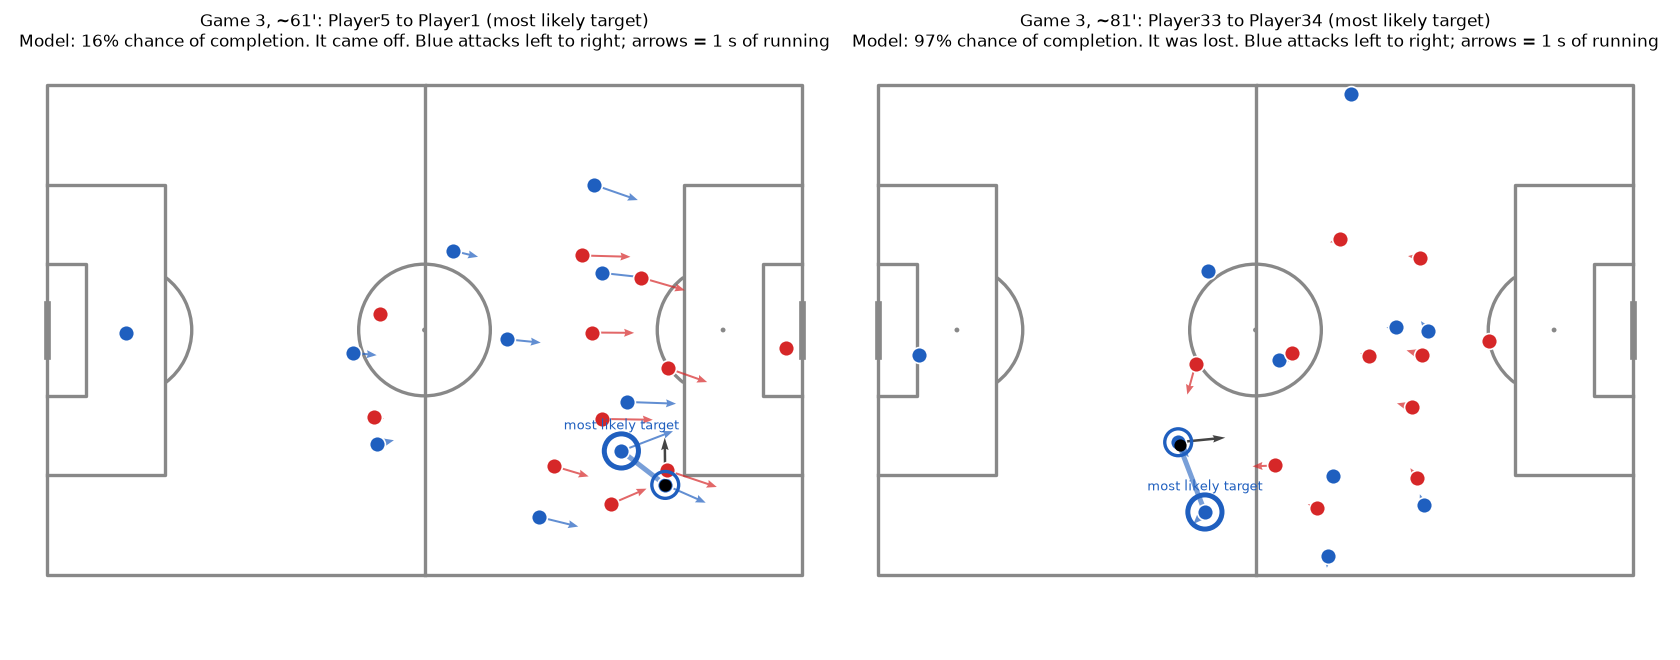

In [2]:
Image(RESULTS / "figures" / "pass_stories.png")

## 10 riskiest completed passes
`target_player` vs `receiver` shows how often the intended-target model picked someone else.

In [3]:
risky = read("step6_riskiest_completed")
print(f"intended target = receiver on {(risky.target_player == risky.receiver).mean():.0%} of these")
risky

intended target = receiver on 10% of these


,match_id,period,approx_minute,passer,target_player,receiver,p_complete,pass_length,target_nearest_opp,passer_nearest_opp,lane_opps,start_x,event_id
0,3,2,94.961,Player17,Player11,Player10,0.098,8.259,7.600,2.204,0,-46.747,3589
1,3,2,88.479,Player14,Player5,Player6,0.106,15.889,4.301,1.498,2,46.523,3355
2,3,2,86.909,Player32,Player34,Player31,0.109,2.253,0.914,2.708,0,-45.829,3260
3,2,2,74.475,Player18,Player26,Player24,0.117,10.113,1.268,3.415,2,46.380,1663
4,3,2,60.627,Player5,Player1,Player1,0.163,7.711,5.196,2.051,1,33.462,2329
5,3,2,58.573,Player24,Player28,Player26,0.166,12.283,9.276,2.744,0,-42.562,2277
6,1,1,35.736,Player7,Player9,Player8,0.190,16.331,2.503,4.335,2,49.035,657
7,3,2,53.025,Player21,Player26,Player24,0.246,18.335,8.913,1.885,1,-38.490,2021
8,3,1,8.176,Player28,Player19,Player23,0.249,7.359,4.817,3.448,1,-34.296,297
9,3,1,32.769,Player18,Player22,Player26,0.254,6.700,2.026,0.637,0,-6.575,1249


## 10 safest failed passes
All have an empty lane to the most likely target: many are probably passes aimed at someone else, i.e. target-model errors rather than completion-model errors.

In [4]:
read("step6_safest_failed")

,match_id,period,approx_minute,passer,target_player,receiver,p_complete,pass_length,target_nearest_opp,passer_nearest_opp,lane_opps,start_x,event_id
0,3,2,80.868,Player33,Player34,NaN,0.974,10.379,11.747,11.083,0,-10.745,3074
1,1,2,70.491,Player16,Player19,NaN,0.972,6.680,8.218,10.289,0,-7.679,1286
2,2,2,59.917,Player9,Player5,NaN,0.968,5.506,7.131,5.875,0,14.205,1328
3,3,2,53.715,Player24,Player23,NaN,0.968,7.781,3.500,8.654,0,8.506,2065
4,1,2,48.126,Player6,Player2,NaN,0.967,7.550,13.807,7.455,0,-11.818,894
5,3,2,78.679,Player31,Player21,NaN,0.966,9.471,6.256,9.545,0,-21.531,2983
6,1,2,48.361,Player22,Player21,NaN,0.962,12.311,12.152,4.108,0,21.019,902
7,2,2,89.935,Player16,Player17,NaN,0.954,18.817,12.755,9.643,0,14.316,1880
8,1,1,24.479,Player10,Player5,NaN,0.949,20.043,14.163,7.793,0,-5.588,487
9,1,1,46.020,Player20,Player15,NaN,0.948,18.263,17.723,10.796,0,-9.539,876


## Completion above expected (per player per match, >= 40 passes)
**Caveat:** a few dozen passes per player, so most differences are within ~2 se of zero. And match-level differences (match 1 completes 75%, match 2 82%) push whole teams up or down: this mixes player skill with match context the model never saw.

In [5]:
cae = read("step6_completion_above_expected", index_col=[0, 1])
cae.assign(beyond_2se=(cae.above_expected.abs() > 2 * cae.se))

passes  completion  expected  above_expected     se  \
match_id passer                                                          
3        Player25      40       0.875     0.749           0.126  0.061   
2        Player6       80       0.912     0.821           0.092  0.040   
         Player9       62       0.839     0.752           0.087  0.050   
         Player20      52       0.865     0.782           0.083  0.055   
1        Player5       40       0.850     0.767           0.083  0.062   
3        Player4       51       0.804     0.737           0.067  0.055   
2        Player5       88       0.875     0.808           0.067  0.039   
         Player4       65       0.892     0.827           0.065  0.044   
         Player1       55       0.782     0.719           0.063  0.055   
         Player15      64       0.781     0.719           0.063  0.051   
         Player21      58       0.862     0.802           0.060  0.050   
3        Player24      73       0.904     0.846           0.058  0.038   
2        Player3       40       0.825     0.776           0.049  0.060   
         Player18      52       0.808     0.763           0.044  0.055   
1        Player3       45       0.800     0.756           0.044  0.057   
         Player12      57       0.895     0.855           0.040  0.045   
2        Player7       64       0.828     0.791           0.037  0.048   
         Player8       55       0.800     0.765           0.035  0.053   
         Player2       41       0.829     0.803           0.026  0.055   
3        Player2       40       0.850     0.828           0.022  0.054   
1        Player4       53       0.792     0.783           0.010  0.053   
3        Player3       66       0.848     0.843           0.005  0.040   
1        Player7       55       0.782     0.780           0.002  0.050   
         Player6       44       0.841     0.843          -0.003  0.053   
3        Player20      63       0.810     0.819          -0.010  0.044   
         Player5       57       0.772     0.791          -0.019  0.050   
1        Player21      74       0.838     0.857          -0.019  0.039   
3        Player19      55       0.818     0.838          -0.020  0.044   
         Player6       64       0.797     0.817          -0.020  0.046   
2        Player16      59       0.847     0.868          -0.020  0.041   
3        Player1       73       0.740     0.763          -0.023  0.045   
         Player23      53       0.830     0.854          -0.024  0.047   
         Player21      54       0.741     0.765          -0.024  0.054   
         Player22      52       0.769     0.797          -0.028  0.054   
2        Player17      55       0.836     0.865          -0.029  0.042   
3        Player7       70       0.786     0.828          -0.042  0.043   
1        Player20      41       0.829     0.872          -0.043  0.049   
3        Player13      57       0.807     0.858          -0.051  0.045   
1        Player8       47       0.660     0.713          -0.053  0.059   
         Player17      50       0.720     0.777          -0.057  0.054   
         Player2       55       0.727     0.813          -0.085  0.048   
         Player15      44       0.682     0.801          -0.119  0.056   
         Player16      47       0.766     0.886          -0.120  0.042   
         Player19      52       0.654     0.833          -0.180  0.050   

                   beyond_2se  
match_id passer                
3        Player25        True  
2        Player6         True  
         Player9        False  
         Player20       False  
1        Player5        False  
3        Player4        False  
2        Player5        False  
         Player4        False  
         Player1        False  
         Player15       False  
         Player21       False  
3        Player24       False  
2        Player3        False  
         Player18       False  
1        Player3        False  
         Player12       False  
2        Player7        False  
      

In [6]:
cae.groupby(level="match_id")["above_expected"].mean().rename("mean above expected per match")

match_id
1   -0.035714
2    0.048133
3    0.001133
Name: mean above expected per match, dtype: float64